# Analysis AI-Team (pair B): Phase II

Maximilian Hammer (pair B, AI-aided in Phase II). Q2 and Q3, continuing from `phase1_Human_max.ipynb`.
AI use (Claude) is recorded in `ai-interactions/phase2_ai_log.md`.

**Story.** StreetCLIP picks the country whose **prompt embedding** is closest to the **image embedding**. In Phase I we found that the biggest confident error (US -> Georgia) comes from the prompt, and that the landscape is the strongest visual clue. In Phase II we open both sides:

- **Q2: The word "Georgia" belongs to the US South.** Image embeddings on a map, image space vs. text space, prompt variants
- **Q3: The model looks at the landscape, and that is also its weak spot.** Grad-CAM vs. masking, heat budget of errors, landscape concepts inside countries

Note: `cfg.show()` in the setup cell prints the defaults from `shared/` (subregion prompt, half precision). The overrides below it and in the next cell are what this notebook uses: paper prompt, float32.

### Load and Import

In [49]:
import os, sys
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
os.chdir(ROOT)
sys.path.insert(0, str(ROOT))

# --- General libraries --------------------------------------------------
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import plotly.express as px          # interactive world map
import plotly.graph_objects as go    # confusion arcs, custom figures
from IPython.display import display
import torch
from tqdm.auto import tqdm

# --- Shared setup -------------------------------------------------------
from shared.data import Config, CountryMapper, OSV5MDataset, MetadataDecoder
from shared.models import (GeoCLIPModel, PredictionRunner, Segmenter, TextDetector,
                           Inpainter, fit_image, fit_mask, free_gpu_memory, get_device)
from shared.masking import MaskApplier
cfg = Config()

# --- Load groups own py files -------------------------------------------
from pair_b.q2_helpers import (relation_features, image_stats, ego_share, seq_share,
                               gallery, model_view)

print("PyTorch", torch.__version__, "| CUDA build", torch.version.cuda)
device = get_device(cfg.device)
if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
    torch.cuda.reset_peak_memory_stats()

# ---------------- change settings here ----------------
cfg.images_per_country = 50
cfg.use_clip_baseline = False        # True -> downloads the original CLIP once (~1.7 GB)
cfg.crop_mode = "center_crop"        # "center_crop" | "pad" | "squash"
cfg.candidate_list = "v1"            # "v1" | "all_test_locations"
cfg.fill_mode = "gray"               # "gray" | "blur" | "inpaint" (inpaint downloads LaMa, ~200 MB)
cfg.batch_size = 32
cfg.num_workers = 4                  # set to 0 if image loading hangs (e.g. on Windows)
# ------------------------------------------------------

cfg.check()
cfg.show()

mapper = CountryMapper("resources/country_aliases.csv")
dataset = OSV5MDataset(cfg, mapper).load()      # no download, already on disk
decoder = MetadataDecoder()

run_name = f"streetclip_{cfg.candidate_list}_{cfg.crop_mode}"   # streetclip_v1_center_crop
preds, logits, embeds, info = PredictionRunner.load(f"results/shared/{run_name}")
preds = decoder.decode(preds)        # adds climate / land-cover / drive-side names

pilot_ids = dataset.build_pilot()    # loads the shared resources/pilot_ids.csv
print(f"{len(preds):,} predictions | {len(pilot_ids):,} pilot images | model: {info['model']}")
# Q3 uses the paper prompt, independent of the default in shared/
cfg.prompt_template = "A Street View photo in {country}."
print("main run prompt:", info["prompt_template"], "| Q3 prompt:", cfg.prompt_template)

PyTorch 2.11.0+cu128 | CUDA build 12.8
GPU: NVIDIA GeForce RTX 4070 Laptop GPU
seed                   42
device                 auto
data_dir               data
results_dir            results
resources_dir          resources
images_per_country     50
streetclip_model       geolocal/StreetCLIP
use_clip_baseline      False
clip_model             openai/clip-vit-large-patch14-336
prompt_template        A Street View photo in {country}, {subregion}.
candidate_list         v1
crop_mode              center_crop
batch_size             32
num_workers            4
half_precision         True
top_k                  10
segmentation_model     facebook/mask2former-swin-large-mapillary-vistas-semantic
fill_mode              gray
blur_radius            25
mask_dilation_px       5
num_random_controls    3
lama_url               https://github.com/enesmsahin/simple-lama-inpainting/releases/download/v0.1.0/big-lama.pt
210,122 predictions | 9,578 pilot images | model: geolocal/StreetCLIP
main run prompt:

In [50]:
# Phase II settings (setup cell above stays the same as in Phase I)
cfg.half_precision = False           # Grad-CAM needs gradients, so float32
GRADCAM_BATCH = 8                    # set lower if the GPU runs out of memory
OUT_DIR = Path("results/pair_b/phase2")
OUT_DIR.mkdir(parents=True, exist_ok=True)

from scipy.stats import spearmanr
from pair_b.gradcam_phase2 import make_cam, heatmaps, cached_text_mask
from pair_b.embeddings_phase2 import embed_texts, normalize, US_STATE_CODES

attrs = mapper.table
ELEMENT_COLORS = {"road": (0.5, 0.5, 0.5), "vegetation": (0.2, 0.7, 0.2), "sky": (0.4, 0.7, 1.0),
                  "buildings": (0.8, 0.4, 0.2), "vehicles": (0.9, 0.1, 0.1),
                  "signs_poles": (1.0, 0.85, 0.0), "text": (1.0, 0.0, 1.0)}

def read_csv(path):
    # "NA" is Namibia, not a missing value
    return pd.read_csv(path, dtype={"id": str}, keep_default_na=False, na_values=[""])

def image_embeddings(rows):
    # cached image embeddings of the main run (same row order as preds), normalized
    x = embeds[rows].astype(np.float32)
    return normalize(x)

assert len(preds) == len(embeds)
assert (preds.index.values == np.arange(len(preds))).all()
df = preds[preds["representable"]].copy()          # index = row in embeds / logits
df["correct"] = df["correct"].astype(bool)

In [51]:
# One model for the text embeddings (Q2, Q3.4) and for Grad-CAM (Q3)
model = GeoCLIPModel(cfg.streetclip_model, cfg)
candidates = mapper.candidates(cfg.candidate_list)
model.set_candidates(candidates, mapper.prompts(candidates, cfg.prompt_template))
assert model.labels == info["labels"]               # same order as the cached logits
print("dtype:", model.dtype, "|", len(candidates), "candidates | example:", model.prompts[0])

text_emb = model.text_embeds.cpu().numpy()          # one row per candidate country
label_pos = {}
for i, c in enumerate(model.labels):
    label_pos[c] = i
cam = make_cam(model)                                # freezes the weights (only matters for Grad-CAM)
segmenter = Segmenter(cfg)                           # label maps come from the cache (data/masks/)
applier = MaskApplier(cfg)                           # same masking as in Phase I

Loading weights: 100%|██████████| 590/590 [00:00<00:00, 39307.44it/s]


dtype: torch.float32 | 197 candidates | example: A Street View photo in Andorra.


Loading weights: 100%|██████████| 758/758 [00:00<00:00, 947.16it/s] 
[transformers] Mask2FormerForUniversalSegmentation LOAD REPORT from: facebook/mask2former-swin-large-mapillary-vistas-semantic
Key                                                                                                                      | Status     | 
-------------------------------------------------------------------------------------------------------------------------+------------+-
model.pixel_level_module.encoder.swin.encoder.layers.{0, 1, 2, 3}.blocks.{0...17}.attention.self.relative_position_index | UNEXPECTED | 
model.pixel_level_module.encoder.swin.layernorm.bias                                                                     | MISSING    | 
model.pixel_level_module.encoder.swin.layernorm.weight                                                                   | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch

# Q2: The word "Georgia" belongs to the US South

**From Phase I:** 25 % of the confident errors are name clashes, almost all US -> Georgia (2,345 US images from the US Southeast). Clarifying the Georgia prompt removed them, so the error comes from the text.

**Questions for Phase II**
- Where in the US do the images "look like Georgia" to the model, and does the image encoder know US states at all?
- Do real Georgia photos look like the Caucasus (image side ok) while the word "Georgia" looks like the US (text side wrong)?
- Which words free "Georgia" from the US state?

**Measures**
- Score of a country for an image = $100 \cdot \cos(\text{image}, \text{prompt})$, the logit the model uses
- $\cos(a, b) = \frac{a \cdot b}{\|a\|\,\|b\|}$: cosine similarity of two embeddings $a$, $b$ (768 numbers each), 1 = same direction. All embeddings are normalized, so it is just the dot product.
- **Georgia margin** of an image = score("Georgia") − score("United States"). Above 0: the model prefers the country Georgia.

### Q2.1 Every US image on the map
Each dot is one US test image at its GPS position, colour = Georgia margin (cached logits of the main run). Below: the interactive version (zoom, hover for state and prediction).

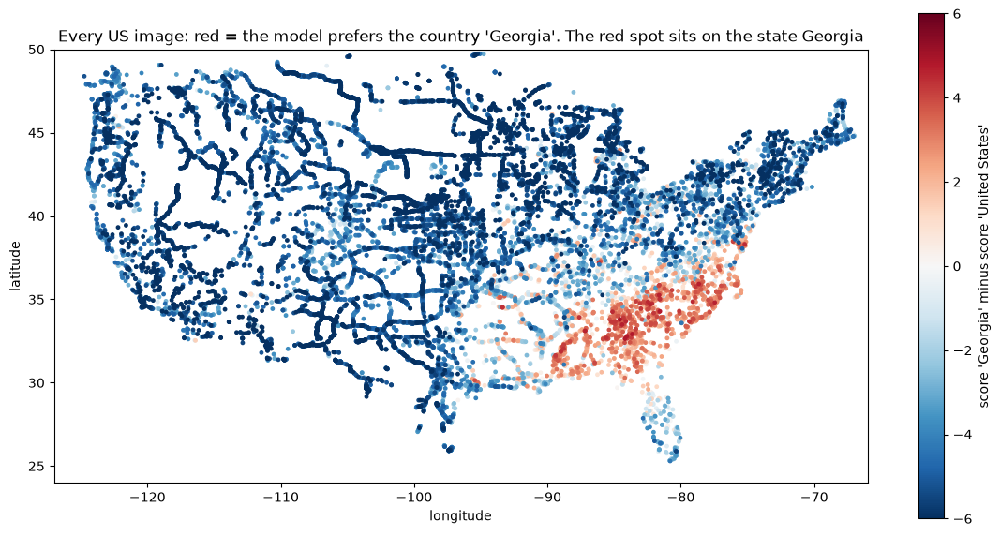

23,875 US images | margin > 0: 11.0%


In [52]:
us = df[df["country_id"] == "US"].copy()
us["margin"] = (logits[us.index.values, label_pos["GE"]].astype(np.float32)
                - logits[us.index.values, label_pos["US"]].astype(np.float32))
order = np.argsort(np.abs(us["margin"].values))     # strongest dots on top

fig, ax = plt.subplots(figsize=(14, 7))
sc = ax.scatter(us["longitude"].values[order], us["latitude"].values[order], c=us["margin"].values[order],
                cmap="RdBu_r", vmin=-6, vmax=6, s=6)
ax.set_xlim(-127, -66)
ax.set_ylim(24, 50)
ax.set_aspect(1.25)
ax.set_xlabel("longitude")
ax.set_ylabel("latitude")
plt.colorbar(sc, label="score 'Georgia' minus score 'United States'")
ax.set_title("Every US image: red = the model prefers the country 'Georgia'. The red spot sits on the state Georgia")
plt.show()

print(f"{len(us):,} US images | margin > 0: {(us['margin'] > 0).mean():.1%}")

In [53]:
fig = px.scatter_geo(us, lat="latitude", lon="longitude", color="margin", scope="usa",
                     color_continuous_scale="RdBu_r", range_color=[-6, 6],
                     hover_name="region", hover_data={"pred_1": True, "prob_1": ":.2f", "margin": ":.1f",
                                                      "latitude": False, "longitude": False},
                     title="US images: Georgia margin (zoom in, hover for details)", height=550)
fig.update_traces(marker=dict(size=3))
fig.show()

**Does the image encoder know US states?** Same images, but now the 50 states + DC as candidates ("A Street View photo in Alabama.", ...).

In [54]:
states = sorted(US_STATE_CODES)
state_emb = embed_texts(model, [cfg.prompt_template.format(country=s) for s in states])

x_us = image_embeddings(us.index.values)
pred_state = []
for k in (x_us @ state_emb.T).argmax(axis=1):
    pred_state.append(states[k])
us["pred_state"] = pred_state

known = us[us["region"].isin(states)]
print(f"state recognised: {(known['pred_state'] == known['region']).mean():.1%} "
      f"of {len(known):,} US images (chance: {1 / len(states):.1%})")

state recognised: 45.7% of 23,875 US images (chance: 2.0%)


**Q2.1 findings:** The map shows a clear red spot that sits right on the state of Georgia and fades out into South Carolina, North Carolina, Alabama and Mississippi. The rest of the US is blue. So the model doesn't confuse random US images with Georgia, it confuses exactly the images from around the state. That also works the other way: with state prompts the model finds the right state in about 46 % of the US images (chance would be 2 %). The image encoder knows US states, which makes sense, since the training captions contain the region ("... in the region of Georgia in United States").

### Q2.2 Image space vs. text space
Left: countries whose image centroid (mean image embedding of all their photos) is closest to the centroid of the real Georgia photos. Right: prompts (countries and US states) closest to the prompt "A Street View photo in Georgia.". Orange = US. The two panels have their own x-axis, because image and text similarities live on different scales.

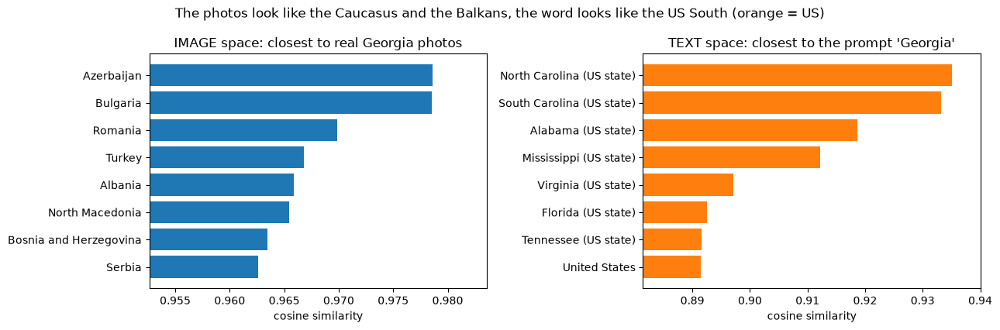

real Georgia photos: 290, predicted as Georgia: 0.0%


In [55]:
cent_ids = []
cent = []
for c, part in df.groupby("country_id"):
    if len(part) >= 30:
        x = image_embeddings(part.index.values)
        cent_ids.append(c)
        cent.append(x.mean(axis=0))
cent = normalize(np.array(cent))

g = cent_ids.index("GE")
sim_img = cent @ cent[g]
image_side = []
for k in np.argsort(-sim_img):
    if cent_ids[k] != "GE" and len(image_side) < 8:
        image_side.append((attrs.loc[cent_ids[k], "prompt_name"], sim_img[k], cent_ids[k] == "US"))

all_text = np.vstack([text_emb, state_emb])
all_names = []
for c in model.labels:
    all_names.append(attrs.loc[c, "prompt_name"])
for s in states:
    all_names.append(f"{s} (US state)")
sim_txt = all_text @ text_emb[label_pos["GE"]]
text_side = []
for k in np.argsort(-sim_txt):
    if all_names[k] not in ["Georgia", "Georgia (US state)"] and len(text_side) < 8:
        is_us = "US state" in all_names[k] or all_names[k] == "United States"
        text_side.append((all_names[k], sim_txt[k], is_us))

fig, axes = plt.subplots(1, 2, figsize=(13, 4.3))
y = np.arange(8)
for ax, side, title in [(axes[0], image_side, "IMAGE space: closest to real Georgia photos"),
                        (axes[1], text_side, "TEXT space: closest to the prompt 'Georgia'")]:
    values = []
    colors = []
    for name, v, is_us in side:
        values.append(v)
        if is_us:
            colors.append("tab:orange")
        else:
            colors.append("tab:blue")
    names = []
    for name, v, is_us in side:
        names.append(name)
    ax.barh(y, values, color=colors)
    ax.set_xlim(min(values) - 0.01, max(values) + 0.005)
    ax.set_yticks(y, names)
    ax.invert_yaxis()
    ax.set_xlabel("cosine similarity")
    ax.set_title(title)
plt.suptitle("The photos look like the Caucasus and the Balkans, the word looks like the US South (orange = US)")
plt.tight_layout()
plt.show()

ge = df[df["country_id"] == "GE"]
print(f"real Georgia photos: {len(ge)}, predicted as Georgia: {(ge['pred_1'] == 'GE').mean():.1%}")

**Q2.2 findings:** The real Georgia photos are closest to Azerbaijan, Bulgaria, Romania and Turkey, so the image side is completely plausible. The word "Georgia" on the other hand is closest to North Carolina, South Carolina, Alabama and Mississippi, and the whole top 8 is American. So the image encoder did its job, the text encoder sends the word to the wrong place. That's why 0 of 290 real Georgia photos are recognised.

### Q2.3 Prompt dial: which words free "Georgia"?
We only replace the Georgia prompt (all other 196 prompts stay the same) and score the cached image embeddings again. Left: US photos that go to Georgia. Right: real Georgia photos that are recognised.

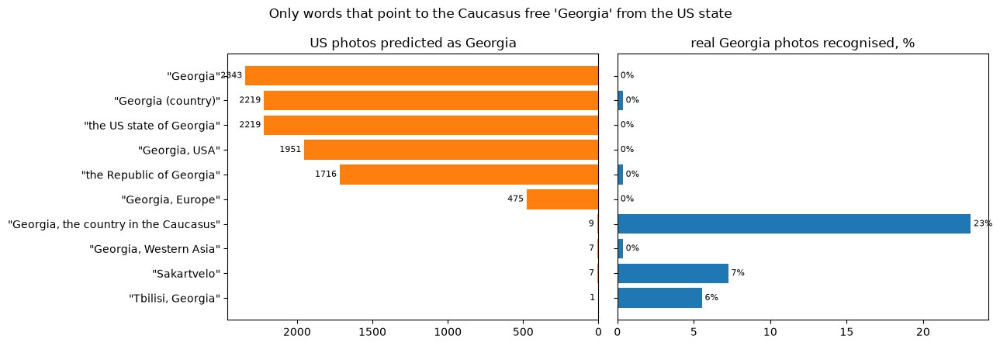

In [56]:
VARIANTS = ["Georgia", "the US state of Georgia", "Georgia (country)", "Georgia, USA",
            "the Republic of Georgia", "Georgia, Europe", "Georgia, the country in the Caucasus",
            "Sakartvelo", "Georgia, Western Asia", "Tbilisi, Georgia"]
variant_emb = embed_texts(model, [cfg.prompt_template.format(country=v) for v in VARIANTS])
x_ge = image_embeddings(ge.index.values)

rows = []
for k, v in enumerate(VARIANTS):
    t = text_emb.copy()
    t[label_pos["GE"]] = variant_emb[k]
    us_to_ge = int(((x_us @ t.T).argmax(axis=1) == label_pos["GE"]).sum())
    ge_found = ((x_ge @ t.T).argmax(axis=1) == label_pos["GE"]).mean()
    rows.append({"prompt": f'"{v}"', "us_to_georgia": us_to_ge, "georgia_recognised": ge_found})
dial = pd.DataFrame(rows).sort_values("us_to_georgia")

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5), sharey=True)
y = np.arange(len(dial))
axes[0].barh(y, dial["us_to_georgia"], color="tab:orange")
axes[0].set_yticks(y, dial["prompt"])
axes[0].invert_xaxis()
axes[0].set_title("US photos predicted as Georgia")
axes[1].barh(y, dial["georgia_recognised"] * 100, color="tab:blue")
axes[1].set_title("real Georgia photos recognised, %")
for k, (a, b) in enumerate(zip(dial["us_to_georgia"], dial["georgia_recognised"])):
    axes[0].text(a, k, f"{a} ", ha="right", va="center", fontsize=8)
    axes[1].text(b * 100, k, f" {b:.0%}", va="center", fontsize=8)
plt.suptitle("Only words that point to the Caucasus free 'Georgia' from the US state")
plt.tight_layout()
plt.show()

**Q2.3 findings:** "Georgia (country)", "the Republic of Georgia" or even "Georgia, USA" barely change anything (1,700 to 2,300 US photos still go to Georgia). The word only lets go of the US once there is a word that belongs to the Caucasus: "Caucasus", "Western Asia", "Tbilisi" or "Sakartvelo" bring it down to 1 to 9 images. But only "the country in the Caucasus" really recognises real Georgia photos (23 %). So the model has learned "Georgia" mostly as the US state, and the country only exists via its neighbours.

**Quick check, training coverage:** are prompts of countries outside the paper's list more "crowded" (very similar to another prompt), which could explain their overconfidence from Phase I F1?

In [57]:
sim = text_emb @ text_emb.T
np.fill_diagonal(sim, -1)
crowd = pd.Series(sim.max(axis=1), index=model.labels)

per_country = df.groupby("country_id").agg(n=("id", "size"), confidence=("prob_1", "mean"),
                                           accuracy=("correct", "mean")).reset_index()
per_country = per_country[per_country["n"] >= 30]
per_country["overconfidence"] = per_country["confidence"] - per_country["accuracy"]
per_country["crowding"] = per_country["country_id"].map(crowd)
per_country["in_list"] = per_country["country_id"].map(attrs["in_paper_training_list"]).astype(int) == 1

r, p = spearmanr(per_country["crowding"], per_country["overconfidence"])
print(f"crowding vs. overconfidence: Spearman r = {r:.2f} (p = {p:.3f}, {len(per_country)} countries)")
print("median crowding:", per_country.groupby("in_list")["crowding"].median().round(3).to_dict())

crowding vs. overconfidence: Spearman r = 0.14 (p = 0.074, 171 countries)
median crowding: {False: 0.8939999938011169, True: 0.9039999842643738}


## Answer to Q2 (Phase II)

- **Where does the confident error come from?** From the text encoder. The word "Georgia" sits among the US-state prompts (Q2.2), while real Georgia photos sit next to the Caucasus and the Balkans. So the image side is fine.
- **What did the model learn?** It knows US states from the images (about 46 % correct, chance 2 %), and photos from the area around the state of Georgia get a high "Georgia" score (Q2.1). Most likely the training captions with region names taught it "Georgia = US Southeast".
- **How to fix it:** only words that point to the Caucasus help (Q2.3). This confirms the Phase I prompt fix, and now we know why it works.
- **Training coverage** (second part of Q2) stays unanswered from the inside as well: a quick test showed that prompts of unlisted countries are not more "crowded" in the text space (median similarity to the closest prompt 0.894 vs. 0.904, r = 0.14 with overconfidence). Pair A's kNN comparison (CLIP vs. StreetCLIP) also found no clear training-list effect.
- **Limitations:** state prompts use the same template as countries; the 46 % is zero-shot over 51 candidates, not a trained classifier; centroid similarities of images and texts are on different scales and are only compared as rankings.

# Q3: The model looks at the landscape, and that is also its weak spot

**From Phase I (masking):** vegetation is the strongest clue (−8.1 pts vs. a random area of the same size), then buildings (−6.3); the sky is not a clue (+1.8).

**Questions for Phase II**
- Does the model also **look** at these elements (Grad-CAM), and where do the two techniques disagree?
- Where does the model look when it is **confidently wrong**?
- **Which** landscape did it learn, and which kinds of scenes help or hurt inside a country?

**Grad-CAM per element** (for one image and one element $e$):

$$\text{heat share}_e = \frac{\sum_{p \in e} h_p}{\sum_{p} h_p} \qquad \text{extra heat}_e = \text{heat share}_e - \frac{|e|}{N}$$

- $h_p$ = Grad-CAM value of pixel $p$ (0 to 1), $p \in e$ = pixels of element $e$ after the center crop
- $|e|$ = number of pixels of $e$, $N$ = all pixels (336 · 336)
- extra heat > 0: the model looks at the element more than its size would suggest

### Q3.1 Grad-CAM vs. masking on the same 3,660 images

In [58]:
q3 = read_csv("results/pair_b/q3_masking.csv")
orig = q3[q3["kind"] == "original"][["id", "p_true"]].rename(columns={"p_true": "p_true_0"})
q3 = q3.merge(orig, on="id")
q3["d_true"] = (q3["p_true"] - q3["p_true_0"]) * 100

elem = q3[q3["kind"] == "element"]
ctrl = q3[q3["kind"] == "control"].groupby(["id", "element"])[["d_true"]].mean().reset_index()
pairs = elem.merge(ctrl, on=["id", "element"], suffixes=("", "_ctrl"))
pairs["d_true_adj"] = pairs["d_true"] - pairs["d_true_ctrl"]

images = q3[q3["kind"] == "original"][["id", "country_id", "orig_pred", "p_true_0"]].reset_index(drop=True)
print(f"{len(images):,} images | {len(pairs):,} (image, element) pairs from Phase I")

3,660 images | 14,105 (image, element) pairs from Phase I


Grad-CAM for the true country (cached in `q3_gradcam.csv`, already done images are skipped; about 5 minutes from scratch).

In [59]:
missing = 0
for image_id in images["id"]:
    if not (Path(cfg.data_dir) / "masks" / f"{image_id}_seg.npz").exists():
        missing += 1
print("images without cached segmentation:", missing)
if missing == 0:
    segmenter.model.to("cpu")        # not needed on the GPU, keeps the memory free for Grad-CAM

out_file = OUT_DIR / "q3_gradcam.csv"
done = set()
if out_file.exists():
    done = set(read_csv(out_file)["id"])
todo = images[~images["id"].isin(done)].reset_index(drop=True)
print(f"{len(done):,} images already done, {len(todo):,} to go")

rows = []
for start in tqdm(range(0, len(todo), GRADCAM_BATCH), desc="Grad-CAM"):
    part = todo.iloc[start:start + GRADCAM_BATCH]
    imgs = []
    for image_id in part["id"]:
        imgs.append(dataset.get_image(image_id))
    heats = heatmaps(cam, model, imgs, part["country_id"].tolist())

    for img, image_id, heat in zip(imgs, part["id"], heats):
        masks = segmenter.element_masks(img, image_id=image_id)
        masks["text"] = cached_text_mask(image_id, img.size, cfg.data_dir)
        total = heat.sum()
        for element, mask in masks.items():
            m = fit_mask(mask, cfg.crop_mode)          # same crop as the model input
            if total > 0:
                heat_share = heat[m].sum() / total
            else:
                heat_share = np.nan
            rows.append({"id": image_id, "element": element, "heat": heat_share, "area": m.mean()})

    if len(rows) > 5000 or start + GRADCAM_BATCH >= len(todo):
        pd.DataFrame(rows).to_csv(out_file, mode="a", header=not out_file.exists(), index=False)
        rows = []

images without cached segmentation: 0
3,660 images already done, 0 to go


Grad-CAM: 0it [00:00, ?it/s]


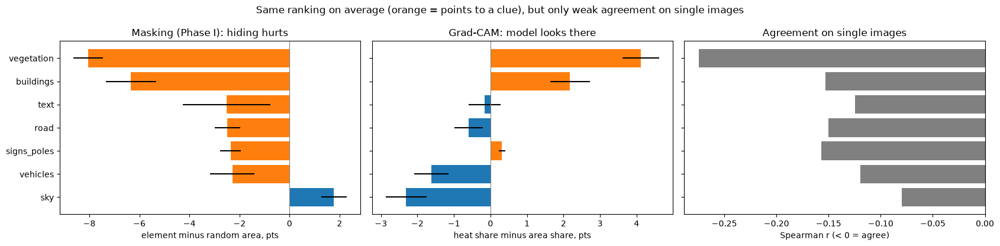

,n,masking,extra,r_image
element,,,,
vegetation,3353,-8.05,4.11,-0.27
buildings,1056,-6.33,2.17,-0.15
text,220,-2.51,-0.16,-0.12
road,3119,-2.48,-0.60,-0.15
signs_poles,2318,-2.35,0.31,-0.16
vehicles,658,-2.29,-1.63,-0.12
sky,3381,1.78,-2.31,-0.08


In [60]:
gc = read_csv(out_file)
gc["extra"] = (gc["heat"] - gc["area"]) * 100
both = pairs.merge(gc, on=["id", "element"])

summary = both.groupby("element").agg(n=("id", "size"), masking=("d_true_adj", "mean"),
                                      masking_std=("d_true_adj", "std"), extra=("extra", "mean"),
                                      extra_std=("extra", "std"))
summary["masking_ci"] = 1.96 * summary["masking_std"] / np.sqrt(summary["n"])
summary["extra_ci"] = 1.96 * summary["extra_std"] / np.sqrt(summary["n"])
r_values = []
for element in summary.index:
    part = both[both["element"] == element]
    r_values.append(spearmanr(part["extra"], part["d_true_adj"])[0])
summary["r_image"] = r_values
summary = summary.sort_values("masking")

y = np.arange(len(summary))
fig, axes = plt.subplots(1, 3, figsize=(17, 4.2), sharey=True)
colors = []
for v in summary["masking"]:
    if v < 0:
        colors.append("tab:orange")
    else:
        colors.append("tab:blue")
axes[0].barh(y, summary["masking"], xerr=summary["masking_ci"], color=colors)
axes[0].set_title("Masking (Phase I): hiding hurts")
axes[0].set_xlabel("element minus random area, pts")
colors = []
for v in summary["extra"]:
    if v > 0:
        colors.append("tab:orange")
    else:
        colors.append("tab:blue")
axes[1].barh(y, summary["extra"], xerr=summary["extra_ci"], color=colors)
axes[1].set_title("Grad-CAM: model looks there")
axes[1].set_xlabel("heat share minus area share, pts")
axes[2].barh(y, summary["r_image"], color="gray")
axes[2].set_title("Agreement on single images")
axes[2].set_xlabel("Spearman r (< 0 = agree)")
for ax in axes:
    ax.axvline(0, color="gray", linewidth=0.8)
axes[0].set_yticks(y, summary.index)
axes[0].invert_yaxis()
plt.suptitle("Same ranking on average (orange = points to a clue), but only weak agreement on single images")
plt.tight_layout()
plt.show()

display(summary[["n", "masking", "extra", "r_image"]].round(2))

**Q3.1 findings:** Both techniques give the same ranking: vegetation gets 4.1 pts more heat than its size (masking: −8.1), buildings +2.2 (masking: −6.3), and the sky gets less heat than its size (−2.3), which fits masking where it isn't a clue. But on single images the agreement is weak (r = −0.28 for vegetation, around −0.15 for the rest). So "where the model looks" and "what it really needs" is not the same thing. The next cell shows what that looks like.

### Q3.2 Same image, two explanations
Picked automatically from the table above: 2 images where both techniques agree on vegetation, 1 where hiding vegetation hurts a lot although the model hardly looks there, and 1 where the model looks there a lot but doesn't need it. Columns: original, vegetation segment, Grad-CAM for the true country, vegetation hidden as in Phase I.

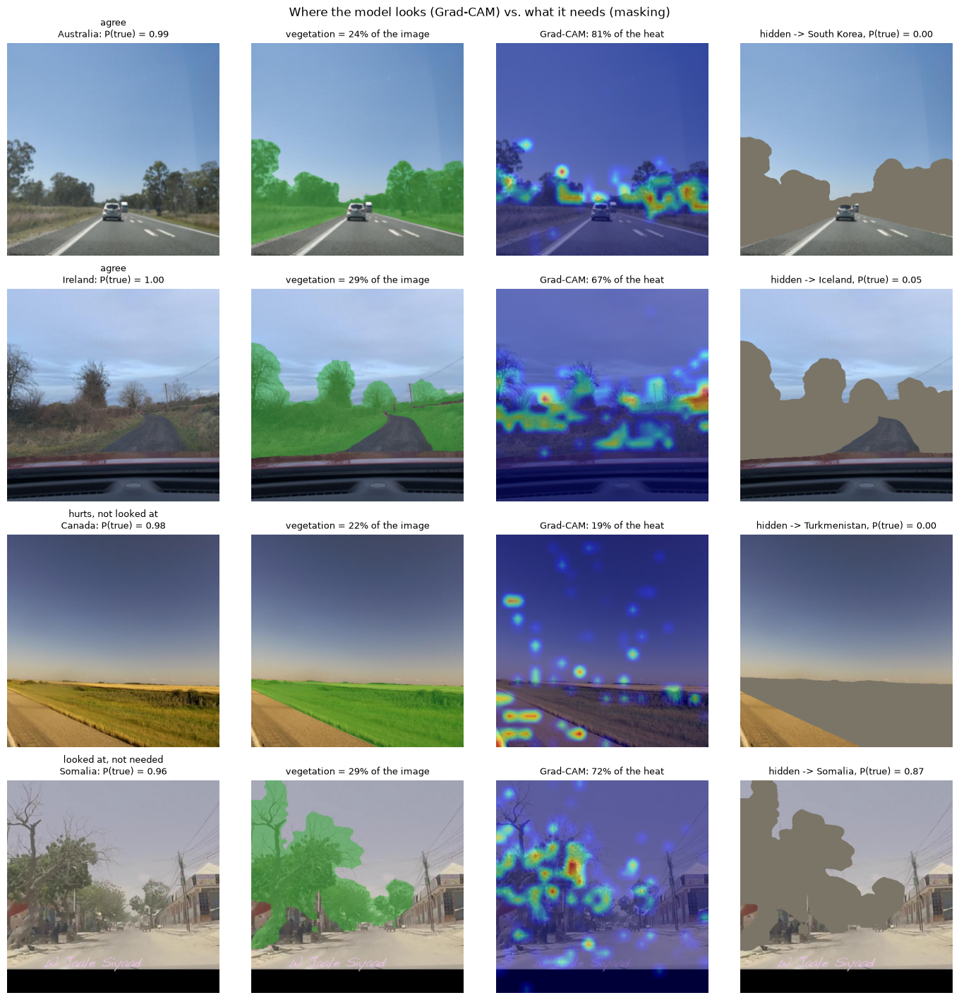

In [61]:
veg = both[both["element"] == "vegetation"]
cases = [("agree", veg[(veg["extra"] > 8) & (veg["d_true_adj"] < -30)].sort_values("d_true_adj").head(2)),
         ("hurts, not looked at", veg[(veg["extra"] < -3) & (veg["d_true_adj"] < -30)].sort_values("d_true_adj").head(1)),
         ("looked at, not needed", veg[(veg["extra"] > 12) & (veg["d_true_adj"] > 5)].sort_values("extra", ascending=False).head(1))]

show = []
for label, part in cases:
    for _, r in part.iterrows():
        show.append((label, r))

fig, axes = plt.subplots(len(show), 4, figsize=(14, 3.6 * len(show)))
for row, (label, r) in enumerate(show):
    img = dataset.get_image(r["id"])
    heat = heatmaps(cam, model, [img], [r["country_id"]])[0]
    mask = segmenter.element_masks(img, image_id=r["id"])["vegetation"]
    m = fit_mask(mask, cfg.crop_mode)
    shown = np.asarray(fit_image(img, cfg.crop_mode)).astype(float) / 255
    overlay = shown.copy()
    overlay[m] = 0.5 * overlay[m] + 0.5 * np.array(ELEMENT_COLORS["vegetation"])
    hidden = applier.apply(img, mask, "vegetation", image_id=r["id"])["image"]
    country = attrs.loc[r["country_id"], "prompt_name"]
    new_pred = attrs.loc[r["new_pred"], "prompt_name"]

    axes[row, 0].imshow(shown)
    axes[row, 0].set_title(f"{label}\n{country}: P(true) = {r['p_true_0']:.2f}", fontsize=9)
    axes[row, 1].imshow(overlay)
    axes[row, 1].set_title(f"vegetation = {m.mean():.0%} of the image", fontsize=9)
    axes[row, 2].imshow(shown)
    axes[row, 2].imshow(heat, cmap="jet", alpha=0.45)
    axes[row, 2].set_title(f"Grad-CAM: {heat[m].sum() / heat.sum():.0%} of the heat", fontsize=9)
    axes[row, 3].imshow(fit_image(hidden, cfg.crop_mode))
    axes[row, 3].set_title(f"hidden -> {new_pred}, P(true) = {r['p_true']:.2f}", fontsize=9)
    for ax in axes[row]:
        ax.axis("off")
plt.suptitle("Where the model looks (Grad-CAM) vs. what it needs (masking)")
plt.tight_layout()
plt.show()

**Q3.2 findings:** In the "agree" rows (e.g. an Australian road with eucalyptus trees) the heat sits on the trees and hiding them destroys the prediction (P from 0.99 to 0.00). The disagreement cases are the interesting ones: on a Canadian field road the model puts only ~20 % of its heat on the field, but without the field it becomes Turkmenistan, so a big, evenly spread area can matter without lighting up in Grad-CAM. The other way round, on a Somali street the trees get most of the heat but hiding them changes nothing, because the street, the houses and the sand still say Somalia. So Grad-CAM shows attention, masking shows necessity, and you need both.

### Q3.3 Heat budget: where does the attention go when the model is confidently wrong?
Same images as Phase I Q2 F2 (`q2_features.csv`): all confident errors and the same number of confident correct images from the same countries. Name-clash errors (mostly US -> Georgia) are their own group. Grad-CAM explains the **predicted** country. Light bars = share of the image (area), dark bars = share of the Grad-CAM heat. About 15 minutes from scratch, cached in `q3_2_gradcam.csv`.

In [62]:
work = read_csv("results/pair_b/q2_features.csv")
groups = []
for is_err, clash in zip(work["is_error"], work["name_clash"]):
    if not is_err:
        groups.append("confident correct")
    elif clash:
        groups.append("name-clash error")
    else:
        groups.append("other confident error")
work["group"] = groups
print(work["group"].value_counts())

out_file_2 = OUT_DIR / "q3_2_gradcam.csv"
done = set()
if out_file_2.exists():
    done = set(read_csv(out_file_2)["id"])
todo = work[~work["id"].isin(done)].reset_index(drop=True)
print(f"{len(done):,} images already done, {len(todo):,} to go")

rows = []
for start in tqdm(range(0, len(todo), GRADCAM_BATCH), desc="Grad-CAM (Q3.3)"):
    part = todo.iloc[start:start + GRADCAM_BATCH]
    imgs = []
    for image_id in part["id"]:
        imgs.append(dataset.get_image(image_id))
    heats = heatmaps(cam, model, imgs, part["pred_1"].tolist())     # explain the predicted country

    for image_id, heat in zip(part["id"], heats):
        labels = np.load(Path(cfg.data_dir) / "masks" / f"q2crop_{image_id}_seg.npz")["labels"]
        total = heat.sum()
        for element, ids in segmenter.element_ids.items():
            m = np.isin(labels, ids)                   # already the cropped model view (336 x 336)
            if total > 0:
                heat_share = heat[m].sum() / total
            else:
                heat_share = np.nan
            rows.append({"id": image_id, "element": element, "heat": heat_share, "area": m.mean()})

    if len(rows) > 5000 or start + GRADCAM_BATCH >= len(todo):
        pd.DataFrame(rows).to_csv(out_file_2, mode="a", header=not out_file_2.exists(), index=False)
        rows = []

group
confident correct        4828
other confident error    3941
name-clash error         1316
Name: count, dtype: int64
10,085 images already done, 0 to go


Grad-CAM (Q3.3): 0it [00:00, ?it/s]


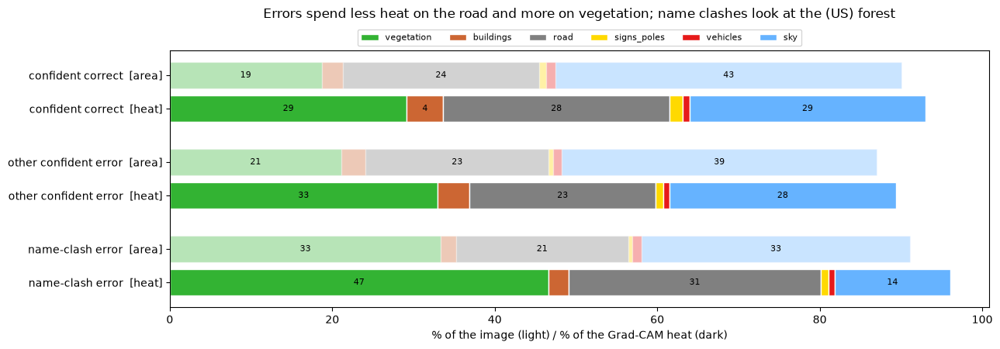

element,vegetation,buildings,road,signs_poles,vehicles,sky
group,,,,,,
confident correct,10.5,1.9,3.7,0.7,-0.3,-13.6
other confident error,11.8,1.0,0.4,0.3,-0.3,-10.8
name-clash error,13.2,0.7,9.8,0.4,-0.3,-18.8


In [63]:
gc2 = read_csv(out_file_2).merge(work[["id", "group"]], on="id")
group_order = ["confident correct", "other confident error", "name-clash error"]
element_order = ["vegetation", "buildings", "road", "signs_poles", "vehicles", "sky"]
heat = gc2.pivot_table(index="group", columns="element", values="heat", aggfunc="mean") * 100
area = gc2.pivot_table(index="group", columns="element", values="area", aggfunc="mean") * 100

fig, ax = plt.subplots(figsize=(13, 4.6))
y = 0
ticks = []
tick_labels = []
for g in group_order:
    for kind, table, alpha in [("area", area, 0.35), ("heat", heat, 1.0)]:
        left = 0
        for e in element_order:
            v = table.loc[g, e]
            label = None
            if g == group_order[0] and kind == "heat":
                label = e
            ax.barh(y, v, left=left, color=ELEMENT_COLORS[e], alpha=alpha, edgecolor="white", label=label)
            if v > 4:
                ax.text(left + v / 2, y, f"{v:.0f}", ha="center", va="center", fontsize=8)
            left += v
        ticks.append(y)
        tick_labels.append(f"{g}  [{kind}]")
        y += 1
    y += 0.6
ax.set_yticks(ticks, tick_labels)
ax.invert_yaxis()
ax.set_xlabel("% of the image (light) / % of the Grad-CAM heat (dark)")
ax.legend(ncol=6, loc="lower center", bbox_to_anchor=(0.5, 1.0), fontsize=8)
ax.set_title("Errors spend less heat on the road and more on vegetation; name clashes look at the (US) forest",
             pad=30)
plt.tight_layout()
plt.show()

display((heat.loc[group_order, element_order] - area.loc[group_order, element_order]).round(1))

**Q3.3 findings:** For correct predictions the model puts 29 % of its heat on vegetation and 28 % on the road. For other confident errors the road drops to 23 % (same road area) and vegetation goes up to 33 %. So when it is confidently wrong it relies more on the landscape and less on the road, i.e. on the part that is shared by many countries. The name-clash errors are extreme: 47 % of the heat goes to vegetation (only 33 % of the area) and the sky drops to 14 %. Combined with Q2: the US-South forest is what the model reads as "Georgia".

### Q3.4 Which scenes help or hurt inside a country?
CLIP can score any text against an image, so we use it as a probe. ~65 scene concepts (vegetation, land, road, signs, buildings, vehicles; suggested by the AI) are scored against **all 210k image embeddings**, and each image gets its best concept. To avoid the country mix (e.g. "eucalyptus" is mostly Australia, which is easy anyway) we compare each image with the other images **of the same country**:

$$\text{lift}_k = \frac{1}{n_k} \sum_{i:\ \text{concept}(i) = k} \left(\text{correct}_i - \text{acc}_{\text{country}(i)}\right)$$

- $k$ = a concept, $n_k$ = number of images whose best concept is $k$
- $\text{correct}_i$ = 1 if image $i$ is predicted correctly, else 0
- $\text{acc}_{\text{country}(i)}$ = accuracy of all images of the same country
- lift > 0: images with this concept are easier than the rest of their country

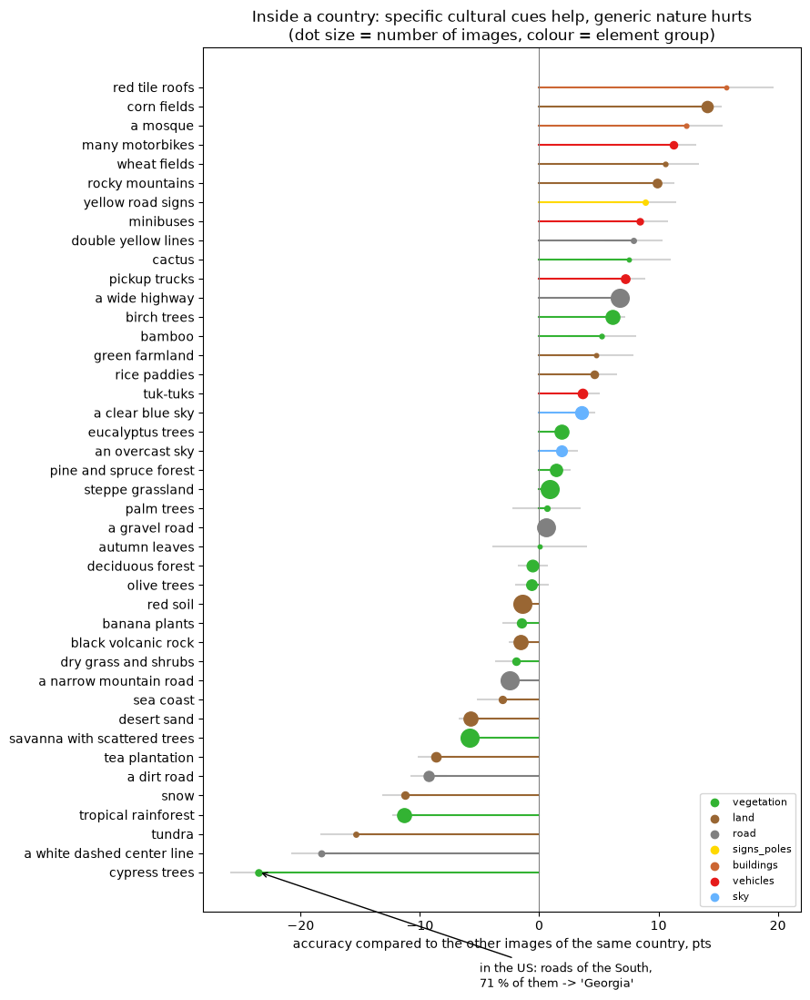

US images with 'cypress trees': 787, predicted as Georgia: 71%


In [64]:
CONCEPT_GROUPS = {
    "vegetation": ["palm trees", "pine and spruce forest", "eucalyptus trees", "birch trees",
                   "tropical rainforest", "deciduous forest", "dry grass and shrubs",
                   "savanna with scattered trees", "steppe grassland", "cactus", "green lawn", "bamboo",
                   "banana plants", "olive trees", "cypress trees", "autumn leaves", "tall reeds"],
    "land": ["desert sand", "red soil", "rocky mountains", "snow", "green farmland", "rice paddies",
             "vineyards", "tea plantation", "wheat fields", "corn fields", "tundra",
             "black volcanic rock", "sea coast", "lake"],
    "road": ["a dirt road", "a gravel road", "a cobblestone street", "a yellow center line",
             "a white dashed center line", "double yellow lines", "red and white curbs",
             "black and white curbs", "a concrete road barrier", "a metal guardrail", "a wide highway",
             "a narrow mountain road"],
    "signs_poles": ["wooden utility poles", "concrete utility poles", "many overhead power lines",
                    "yellow road signs", "blue road signs", "bollards with reflectors"],
    "buildings": ["red tile roofs", "corrugated metal roofs", "colorful painted houses", "wooden houses",
                  "white plastered houses", "brick houses", "high-rise apartment blocks", "a mosque",
                  "a church", "a buddhist temple", "shop signs with text"],
    "vehicles": ["tuk-tuks", "many motorbikes", "pickup trucks", "minibuses"],
    "sky": ["an overcast sky", "a clear blue sky"],
}
concepts = []
concept_group = {}
for group, names in CONCEPT_GROUPS.items():
    for c in names:
        concepts.append(c)
        concept_group[c] = group
concept_emb = embed_texts(model, [f"A Street View photo with {c}." for c in concepts])

rows = df.index.values
best_k = np.zeros(len(rows), dtype=int)
best_p = np.zeros(len(rows))
for start in range(0, len(rows), 20000):
    x = image_embeddings(rows[start:start + 20000])
    scores = 100 * x @ concept_emb.T
    probs = np.exp(scores - scores.max(axis=1, keepdims=True))
    probs = probs / probs.sum(axis=1, keepdims=True)
    best_k[start:start + 20000] = probs.argmax(axis=1)
    best_p[start:start + 20000] = probs.max(axis=1)
df["concept"] = np.array(concepts)[best_k]
df["concept_p"] = best_p

df["country_acc"] = df.groupby("country_id")["correct"].transform("mean")
df["lift"] = df["correct"] - df["country_acc"]
lift = df.groupby("concept").agg(n=("id", "size"), lift=("lift", "mean"), std=("lift", "std"))
lift = lift[lift["n"] >= 500]
lift["ci"] = 1.96 * lift["std"] / np.sqrt(lift["n"])
lift = lift.sort_values("lift")

fig, ax = plt.subplots(figsize=(9, 11))
y = np.arange(len(lift))
GROUP_COLORS = dict(ELEMENT_COLORS)
GROUP_COLORS["land"] = (0.6, 0.4, 0.2)
for k, (c, r) in enumerate(lift.iterrows()):
    color = GROUP_COLORS[concept_group[c]]
    ax.errorbar(r["lift"] * 100, k, xerr=r["ci"] * 100, fmt="none", ecolor="lightgray", zorder=1)
    ax.plot([0, r["lift"] * 100], [k, k], color=color, zorder=2)
    ax.scatter(r["lift"] * 100, k, color=color, s=min(max(r["n"] / 60, 10), 200), zorder=3)
ax.set_yticks(y, lift.index)
ax.axvline(0, color="gray", linewidth=0.8)
ax.set_xlabel("accuracy compared to the other images of the same country, pts")
for group in CONCEPT_GROUPS:
    ax.scatter([], [], color=GROUP_COLORS[group], label=group)
ax.legend(fontsize=8, loc="lower right")
if "cypress trees" in lift.index:
    k = list(lift.index).index("cypress trees")
    ax.annotate("in the US: roads of the South,\n71 % of them -> 'Georgia'", (lift.loc["cypress trees", "lift"] * 100, k),
                xytext=(-5, k - 6), fontsize=9, arrowprops=dict(arrowstyle="->"))
ax.set_title("Inside a country: specific cultural cues help, generic nature hurts\n"
             "(dot size = number of images, colour = element group)")
plt.tight_layout()
plt.show()

us_cypress = df[(df["country_id"] == "US") & (df["concept"] == "cypress trees")]
print(f"US images with 'cypress trees': {len(us_cypress)}, predicted as Georgia: {(us_cypress['pred_1'] == 'GE').mean():.0%}")

**Check of the AI-suggested concepts:** the 4 most confident images of some concepts. If they don't show the concept, the probe isn't reliable for it.

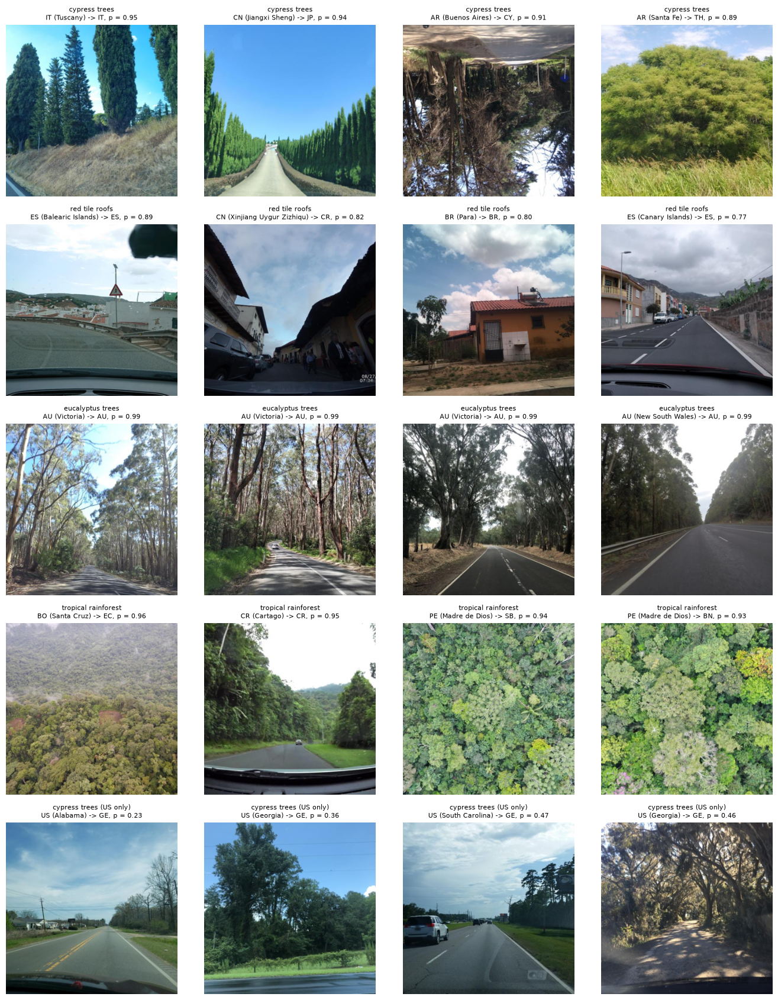

In [65]:
CHECK = ["cypress trees", "red tile roofs", "eucalyptus trees", "tropical rainforest", "cypress trees (US only)"]
N_SHOW = 4

fig, axes = plt.subplots(len(CHECK), N_SHOW, figsize=(3.4 * N_SHOW, 3.4 * len(CHECK)))
for i, concept in enumerate(CHECK):
    if concept == "cypress trees (US only)":
        part = df[(df["concept"] == "cypress trees") & (df["country_id"] == "US")]
        best = part.sample(N_SHOW, random_state=0)           # random US examples, not the best ones
    else:
        best = df[df["concept"] == concept].sort_values("concept_p", ascending=False).head(N_SHOW)
    for j, (_, r) in enumerate(best.iterrows()):
        axes[i, j].imshow(fit_image(dataset.get_image(r["id"]), cfg.crop_mode))
        axes[i, j].set_title(f"{concept}\n{r['country_id']} ({r['region']}) -> {r['pred_1']}, p = {r['concept_p']:.2f}",
                             fontsize=8)
        axes[i, j].axis("off")
plt.tight_layout()
plt.show()

**Q3.4 findings:** Inside a country, images with specific, man-made or cultural cues are easier: red tile roofs (+16 pts), corn fields (+14), mosques (+12), many motorbikes (+11), yellow road signs (+9). Generic nature is harder: tropical rainforest (−11), snow (−11), tundra (−15), dirt roads (−9). At the very bottom is "cypress trees" (−23), and the check gallery shows why: the most confident "cypress" images are real cypresses (Tuscany), but the US images with this label are not cypresses at all, they are ordinary roads with dense green forest in the South (Georgia, Mississippi, the Carolinas, Alabama; low concept scores of 0.1 to 0.5). 71 % of these US images go to "Georgia". So in the US the "cypress" text works like a "US South forest" detector, and that look is exactly what pulls images to the word Georgia. The Q2 error has a visual side too.

Two lessons about the probe: (1) a first version of this plot compared concepts *across* countries and showed "unique landscape = easy" (r = −0.47); inside countries that effect was gone (r = 0.00), it only came from the country mix (AI log #11). (2) A concept name is not what the image shows: "cypress trees" in the US means "Southern forest road", and "tropical rainforest" partly catches aerial drone shots. Without the gallery we would have taken the labels literally.

## Answer to Q3 (Phase II)

- **Does the model look where hiding hurts?** On average yes: same ranking with Grad-CAM and masking (vegetation, then buildings, sky not a clue). On single images only weakly (r ≈ −0.15 to −0.28): big, evenly spread areas can be necessary without lighting up, and highlighted areas can be redundant (Q3.1, Q3.2).
- **Where does it look when it is confidently wrong?** Less on the road, more on vegetation; for name-clash errors almost half the heat goes to the forest (Q3.3).
- **What did it learn about scenes?** Inside a country, specific cultural cues (roofs, mosques, crops, signs) make it more accurate, generic nature makes it less accurate (Q3.4). Phase I found vegetation as the strongest clue; Phase II shows it is also the weak spot when the vegetation isn't specific to one country.
- **Link to Q2:** the confident US -> Georgia error has a text side (the word) and an image side (the dense forest of the US South, which the probe calls "cypress trees").
- **Limitations:** Grad-CAM on the last layer is coarse (24 × 24 patches); masking uses gray blocks; segmentation errors affect both techniques the same way; the concept probe only knows the concepts we give it and the best concept is relative to that list; a concept name is not always what the image shows (US "cypress" = Southern forest roads, "tropical rainforest" includes some aerial shots, see the check).

In [66]:
# free the GPU
del cam, model, segmenter
free_gpu_memory()